# Assignment 4 — Intensity Transformations

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.moon()   # 'moon' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


In [3]:
def plot_hist(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 2.8))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.hist(im.ravel(), bins=256, range=(0, 255), color='gray')
        ax.set_title(t); ax.set_xlim(0, 255)
    plt.tight_layout(); plt.show()

## Question 1

> **Question 1:** WAP to enhance the input image using the Log transform. Assume c = 1.

### Log transform  $\; s = c \, \log(1 + r), \; c = 1$

With c = 1 and r in 0–255, s lies in 0 to log(256) ≈ 5.545, so it is scaled linearly back to 0–255 for display. The log expands dark intensities and compresses bright ones.

Raw log output range: 0.000 to 5.545


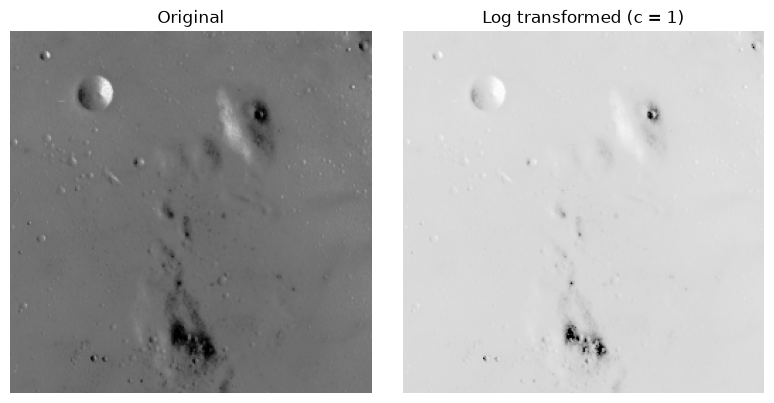

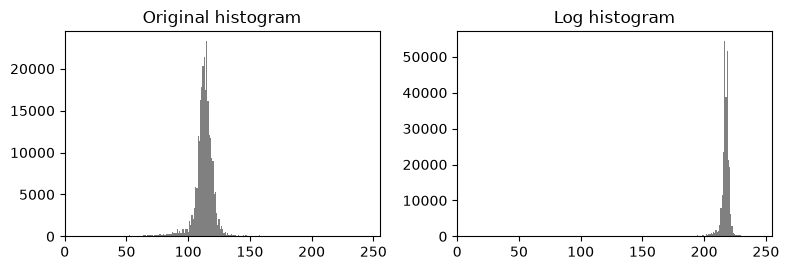

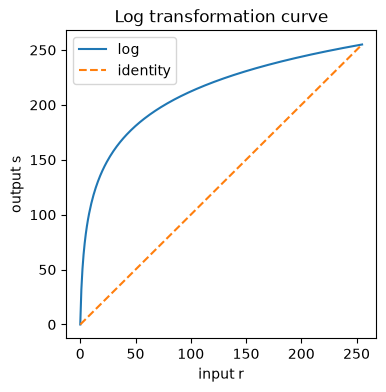

In [4]:
def log_transform(image, c=1):
    r = image.astype(np.float64)
    s = c * np.log(1 + r)                    # s in [0, c*log(256)]
    print(f"Raw log output range: {s.min():.3f} to {s.max():.3f}")
    s = s / (c * np.log(256)) * 255          # scale to the 0-255 display range
    return np.round(s).astype(np.uint8)

log_img = log_transform(img, c=1)
show([img, log_img], ['Original', 'Log transformed (c = 1)'])
plot_hist([img, log_img], ['Original histogram', 'Log histogram'])

r = np.arange(256)
plt.figure(figsize=(4, 4))
plt.plot(r, np.log(1 + r) / np.log(256) * 255, label='log'); plt.plot(r, r, '--', label='identity')
plt.title('Log transformation curve'); plt.xlabel('input r'); plt.ylabel('output s'); plt.legend(); plt.show()

## Question 2

> **Question 2:** WAP to enhance the input image using the Power law / gamma transform. Assume c = 1, and input the value of gamma from the user.

### Power-law (gamma) transform  $\; s = c \, r^{\gamma}, \; c = 1$

Intensities are normalised to [0, 1] first, so with c = 1 the output also stays in [0, 1] and is then multiplied by 255. γ < 1 brightens the image and γ > 1 darkens it.

Enter the value of gamma: no valid input, using default = 0.5


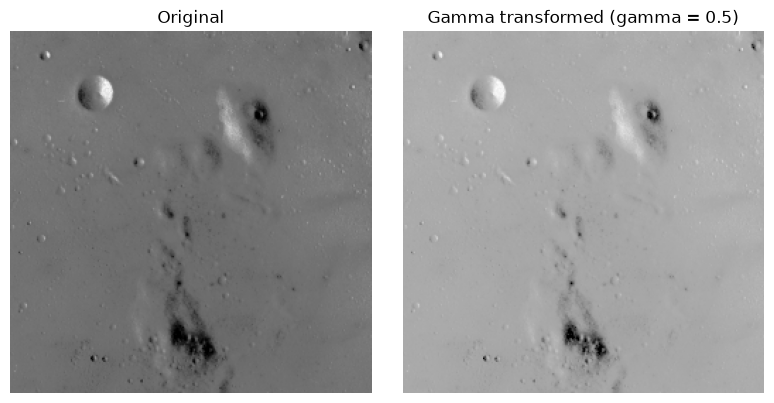

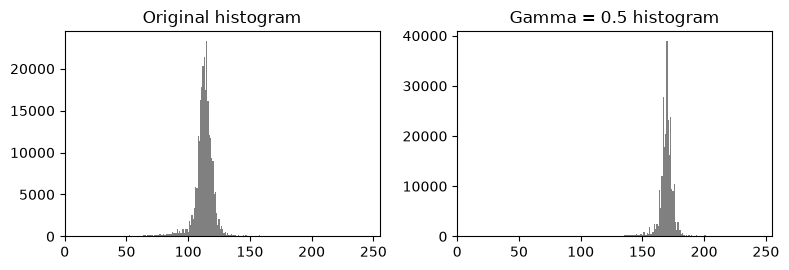

In [5]:
def gamma_transform(image, gamma, c=1):
    r = image.astype(np.float64) / 255.0
    s = c * np.power(r, gamma)
    return np.clip(np.round(s * 255), 0, 255).astype(np.uint8)

gamma = ask("Enter the value of gamma", 0.5)
if gamma <= 0:
    print("gamma must be positive -> using 0.5"); gamma = 0.5

gamma_img = gamma_transform(img, gamma)
show([img, gamma_img], ['Original', f'Gamma transformed (gamma = {gamma:g})'])
plot_hist([img, gamma_img], ['Original histogram', f'Gamma = {gamma:g} histogram'])

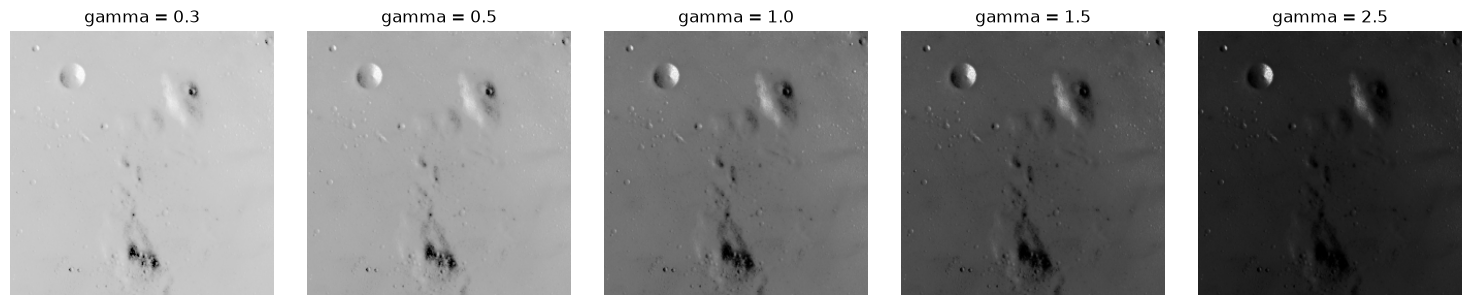

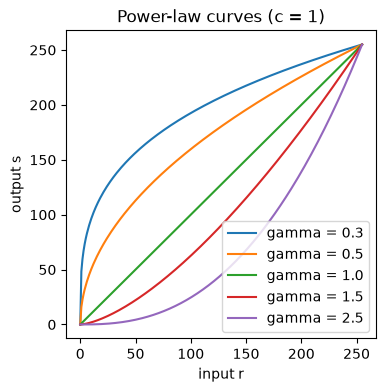

In [6]:
gammas = [0.3, 0.5, 1.0, 1.5, 2.5]
show([gamma_transform(img, g) for g in gammas], [f'gamma = {g}' for g in gammas], size=3)

plt.figure(figsize=(4, 4))
for g in gammas:
    plt.plot(r, 255 * (r / 255) ** g, label=f'gamma = {g}')
plt.title('Power-law curves (c = 1)'); plt.xlabel('input r'); plt.ylabel('output s'); plt.legend(); plt.show()

## Question 3

> **Question 3:** WAP to enhance the input image using Intensity level slicing (Contrast stretching). The input range of intensity values and the desired range of intensity values in the output image are obtained from the user. (Example: the input range of intensity values from 80 to 120 is stretched to 50-150 in the output image.)

### Contrast stretching

The user gives an input range $[r_1, r_2]$ and an output range $[s_1, s_2]$. A piecewise linear function through the points $(0,0), (r_1,s_1), (r_2,s_2), (255,255)$ is applied:

$$
s = \begin{cases}
\dfrac{s_1}{r_1}\, r & 0 \le r < r_1 \\[4pt]
s_1 + \dfrac{s_2 - s_1}{r_2 - r_1}(r - r_1) & r_1 \le r \le r_2 \\[4pt]
s_2 + \dfrac{255 - s_2}{255 - r_2}(r - r_2) & r_2 < r \le 255
\end{cases}
$$

So the range 80–120 (width 40) is stretched to 50–150 (width 100), which increases contrast in that band.

Enter start of INPUT range r1: no valid input, using default = 80
Enter end of INPUT range r2: no valid input, using default = 120
Enter start of OUTPUT range s1: no valid input, using default = 50
Enter end of OUTPUT range s2: no valid input, using default = 150


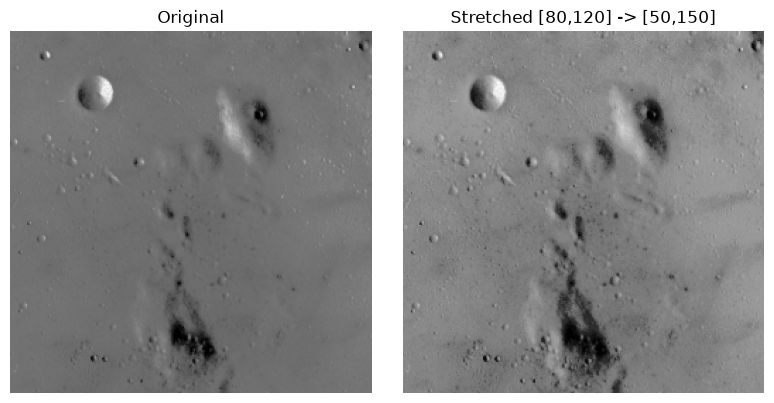

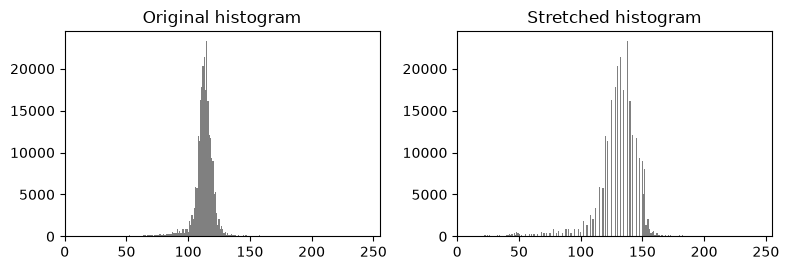

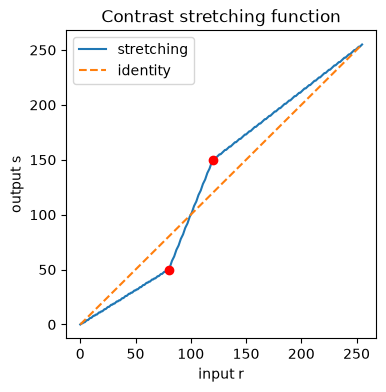

In [7]:
def contrast_stretch(image, r1, r2, s1, s2):
    r = image.astype(np.float64)
    out = np.zeros_like(r)
    low, mid, high = r < r1, (r >= r1) & (r <= r2), r > r2
    out[low] = (s1 / r1) * r[low] if r1 > 0 else s1
    out[mid] = s1 + (s2 - s1) / (r2 - r1) * (r[mid] - r1)
    out[high] = s2 + (255 - s2) / (255 - r2) * (r[high] - r2) if r2 < 255 else s2
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

r1 = ask("Enter start of INPUT range r1", 80, int)
r2 = ask("Enter end of INPUT range r2", 120, int)
s1 = ask("Enter start of OUTPUT range s1", 50, int)
s2 = ask("Enter end of OUTPUT range s2", 150, int)
if not (0 <= r1 < r2 <= 255 and 0 <= s1 <= s2 <= 255):
    print("Invalid ranges -> using the example 80-120 -> 50-150")
    r1, r2, s1, s2 = 80, 120, 50, 150

stretched = contrast_stretch(img, r1, r2, s1, s2)
show([img, stretched], ['Original', f'Stretched [{r1},{r2}] -> [{s1},{s2}]'])
plot_hist([img, stretched], ['Original histogram', 'Stretched histogram'])

plt.figure(figsize=(4, 4))
plt.plot(r, contrast_stretch(r.astype(np.uint8), r1, r2, s1, s2), label='stretching')
plt.plot(r, r, '--', label='identity')
plt.scatter([r1, r2], [s1, s2], color='r', zorder=3)
plt.title('Contrast stretching function'); plt.xlabel('input r'); plt.ylabel('output s'); plt.legend(); plt.show()

### Extra — classic intensity-level slicing
Two common variants are shown for the same range $[r_1, r_2]$: (a) highlight the range in white and make everything else black, (b) highlight the range and keep the rest of the image unchanged.

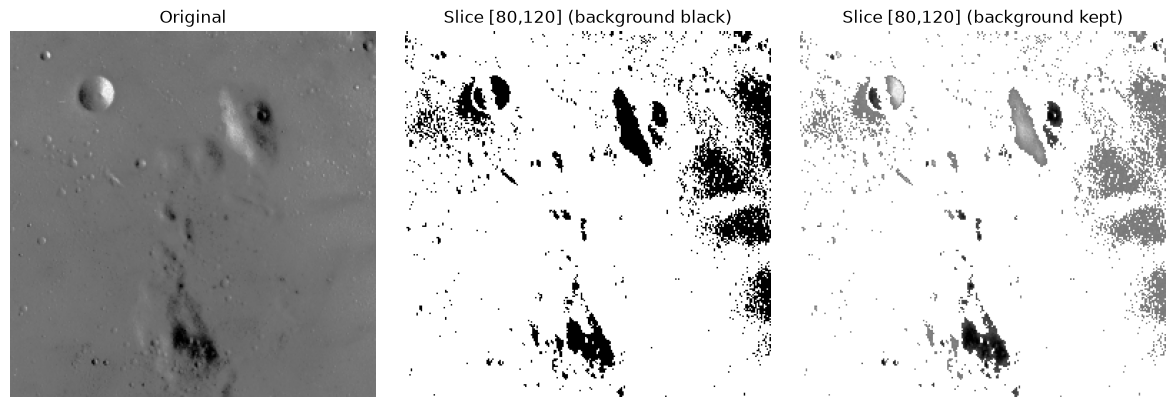

In [8]:
in_range = (img >= r1) & (img <= r2)
slice_a = np.where(in_range, 255, 0).astype(np.uint8)
slice_b = np.where(in_range, 255, img).astype(np.uint8)
show([img, slice_a, slice_b], ['Original', f'Slice [{r1},{r2}] (background black)',
                                f'Slice [{r1},{r2}] (background kept)'])

**Observations:**
- The **log transform** brings out detail in the dark regions of the moon by expanding low intensities.
- **Gamma < 1** brightens the image like the log does, and **gamma > 1** darkens it. One formula covers a whole family of curves.
- **Contrast stretching** spreads the chosen band of intensities (80–120) over a wider output range (50–150), so detail inside that band becomes more visible. Intensities outside the band are compressed.